<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Application-Deployment/blob/main/20261204/Perceptron_Linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Single Perceptron Neural Networks for Linear Regression

**After this assignment you will be able to:**
- Implement a neural network with a single perceptron and one input node for simple linear regression
- Implement forward propagation using matrix multiplication
- Implement a neural network with a single perceptron and two input nodes for multiple linear regression

# Table of Contents

- [ 1 - Simple Linear Regression](#1)
  - [ 1.1 - Simple Linear Regression Model](#1.1)
  - [ 1.2 - Neural Network Model with a Single Perceptron and One Input Node](#1.2)
  - [ 1.3 - Dataset](#1.3)
    - [ Exercise 1](#ex01)
- [ 2 - Implementation of the Neural Network Model for Linear Regression](#2)
  - [ 2.1 - Defining the Neural Network Structure](#2.1)
    - [ Exercise 2](#ex02)
  - [ 2.2 - Initialize the Model's Parameters](#2.2)
    - [ Exercise 3](#ex03)
  - [ 2.3 - The Loop](#2.3)
    - [ Exercise 4](#ex04)
  - [ 2.4 - Integrate parts 2.1, 2.2 and 2.3 in nn_model()](#2.4)
    - [ Exercise 5](#ex05)
- [ 3 - Multiple Linear Regression](#3)
  - [ 3.1 - Multipe Linear Regression Model](#3.1)
  - [ 3.2 - Neural Network Model with a Single Perceptron and Two Input Nodes](#3.2)
  - [ 3.3 - Dataset](#3.3)
  - [ 3.4 - Performance of the Neural Network Model for Multiple Linear Regression](#3.4)
    - [ Exercise 6](#ex06)

## Packages

Let's first import all the packages that you will need during this assignment.

In [14]:
! pip install mglearn -q
import mglearn
import numpy as np
import matplotlib.pyplot as plt

<a name='1'></a>
## 1 - Simple Linear Regression

**Linear regression** is a linear approach for modelling the relationship between a scalar response (**dependent variable**) and one or more explanatory variables (**independent variables**). The case of one independent variable is called **simple linear regression**; for more than one, it is called **multiple linear regression**.

<a name='1.1'></a>
### 1.1 - Simple Linear Regression Model

Simple linear regression model can be written as

$$\hat{y} = wx + b,\tag{1}$$

> where $\hat{y}$ is a prediction of dependent variable $y$ based on independent variable $x$ using a line equation with the slope $w$ and intercept $b$.

Given a set of training data points $(x_1, y_1)$, ..., $(x_m, y_m)$, the aim is to find the "best" fitting line - such parameters $w$ and $b$ that the differences between original values $y_i$ and predicted values $\hat{y}_i = wx_i + b$ are minimum.

You can use a simple neural network model to do that. Vector algebra will be used in the core of the model!

w[0]: 0.393906  b: -0.031804


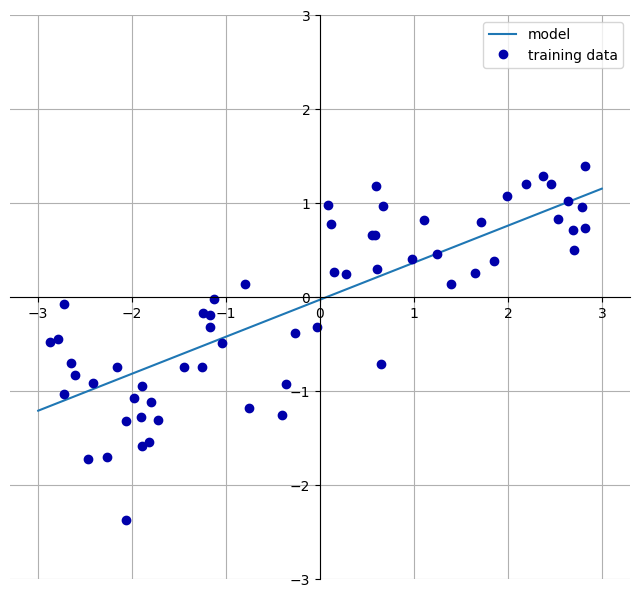

In [17]:
mglearn.plots.plot_linear_regression_wave()

In [80]:
m = 30
X, Y = make_regression(n_samples=m, n_features=1, noise=20, random_state=1)

print(f'Training dataset X: {X.shape}\n')
print(f'Training dataset Y: {Y.shape}')

Training dataset X: (30, 1)

Training dataset Y: (30,)


Text(0, 0.5, '$Y$')

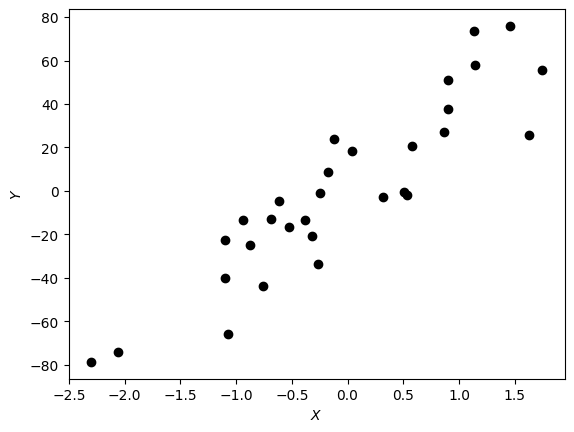

In [59]:
plt.scatter(X,  Y, c="black")
plt.xlabel("$X$"); plt.ylabel("$Y$")

<a name='1.3'></a>
### 1.3 - Dataset

First, let's get the dataset you will work on. The following code will create $m=30$ data points $(x_1, y_1)$, ..., $(x_m, y_m)$ and save them in `NumPy` arrays `X` and `Y` of a shape $(1 \times m)$.

What is the `shape` of the variables `X` and `Y`? In addition, how many training examples do you have?

In [ ]:
### START CODE HERE ### (~ 3 lines of code)
# Shape of variable X.
shape_X = X.shape
# Shape of variable Y.
shape_Y = Y.shape
# Training set size.
m = X.shape[1]
### END CODE HERE ###

print ('The shape of X: ' + str(shape_X))
print ('The shape of Y: ' + str(shape_Y))
print ('I have m = %d training examples!' % (m))


The shape of X: (30, 1)
The shape of Y: (30,)
I have m = 1 training examples!


##### __Expected Output__

```Python
The shape of X: (1, 30)
The shape of Y: (1, 30)
I have m = 30 training examples!
```

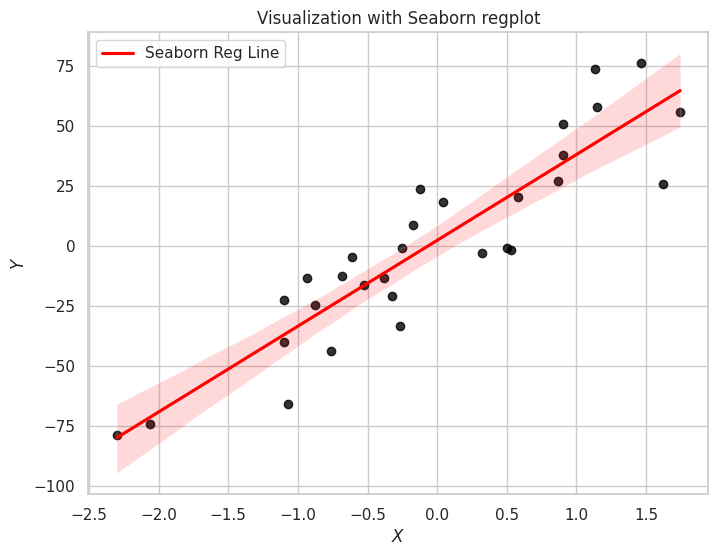

In [81]:
import seaborn as sns
import matplotlib.pyplot as plt

# 그래프 스타일 설정
sns.set_theme(style="whitegrid")

# 1차원 데이터로 변환 후 seaborn regplot 시각화
plt.figure(figsize=(8, 6))
sns.regplot(x=X.ravel(), y=Y.ravel(), color="black",
            line_kws={"color": "red", "label": "Seaborn Reg Line"})

plt.xlabel("$X$"); plt.ylabel("$Y$")
plt.title("Visualization with Seaborn regplot")
plt.legend()

**Weight** ($w$) and **bias** ($b$) are the parameters which will get updated when you will **train** the model. They are initialized to some random value or set to 0 and updated as the training progresses. The bias is analogous to a weight independent of any input node. It makes the model more flexible.

The perceptron output calculation is straightforward: first compute the product of $x$ and weight $w$ and the add the bias:

$$z = w x + b\tag{2}$$

The **output layer** of the single perceptron has only one node $\hat{y} = z$.

Putting it all together, mathematically the single perceptron neural network model can be expressed as:

\begin{align}
z^{(i)} &=  w x^{(i)} + b,\\
\hat{y}^{(i)} &= z^{(i)},
\tag{3}\end{align}

where $x^{(i)}$ represents the $i$-th training example and $\hat{y}^{(i)}$ will be the prediction based on that example, $i = 1, \dots, m$.

Now, you can compare the resulting vector of the predictions $\hat{Y}$ ($1 \times m$) with the original vector of data $Y$. This can be done with the so called **cost function** that measures how close your vector of predictions to the training data. It evaluates how well the parameters $w$ and $b$ work to solve the problem. There are many different cost functions available depending on the nature of your problem. For your simple neural network you can calculate it as:

$$\mathcal{L}\left(w, b\right)  = \frac{1}{2m}\sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2.\tag{5}$$

The aim is to minimize the cost function during the training, which will minimize the differences between original values $y_i$ and predicted values $\hat{y}_i$ (division by $2m$ is taken just for scaling purposes).

## **How to find the line that represents the scattered X and Y ?**

- Features(X) = matrix
- Target(y) = vector

In [71]:
# @title **1. 직선의 절편과 기울기 search**
from scipy.stats import uniform
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import RandomizedSearchCV

# 1. scikit-learn 호환 직선 모델 사용자정의
class LinearGridEstimator(BaseEstimator, RegressorMixin):
    def __init__(self, w=0.0, b=0.0):
        self.w = w
        self.b = b

    def fit(self, X, y):
        return self

    def predict(self, X):
        return self.w * X.ravel() + self.b

# 2. 탐색할 연속 균등 분포 정의
param_distributions = {
    'w': uniform(loc=20.0, scale=30.0),   # [20.0, 50.0] 구간 탐색 (실제 기울기 약 35.8)
    'b': uniform(loc=-10.0, scale=30.0)   # [-10.0, 20.0] 구간 탐색 (실제 절편 약 3.5)
}

# 3. RandomizedSearchCV 실행 (전체 30개 샘플 사용)
random_search = RandomizedSearchCV(
    estimator=LinearGridEstimator(),
    param_distributions=param_distributions,
    n_iter=5000,
    scoring='neg_mean_squared_error',
    cv=2,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

# X와 Y의 30개 샘플 크기를 명확히 맞춰줍니다.
X_1d = X.reshape(-1, 1)
y_1d = Y.ravel() # 대문자 Y를 사용하여 30개 타겟 데이터를 가져옵

random_search.fit(X_1d, y_1d)

best_w = random_search.best_params_['w']
best_b = random_search.best_params_['b']
best_mse = -random_search.best_score_

print(f"최적 직선식: y = {best_w:.4f}x + {best_b:.4f}")
print(f"5-Fold CV MSE: {best_mse:.5f}")

Fitting 2 folds for each of 5000 candidates, totalling 10000 fits
최적 직선식: y = 35.5884x + 2.0822
5-Fold CV MSE: 282.52202


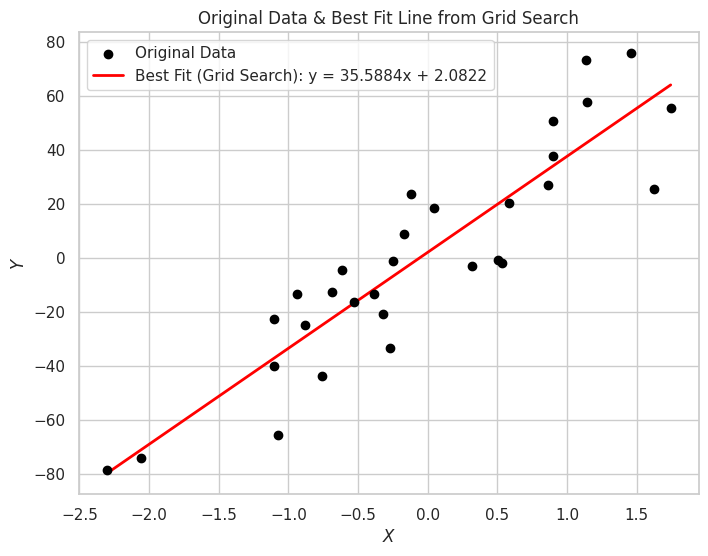

In [72]:
plt.figure(figsize=(8, 6))
plt.scatter(X_1d, Y_1d, color="black", label="Original Data", zorder=3)

# Random Grid Search의 최적 가중치와 편향을 사용해 예측선 그리기
X_line = np.linspace(X_1d.min(), X_1d.max(), 100)
Y_line = best_w * X_line + best_b

plt.plot(X_line, Y_line, color="red", linewidth=2, label=f"Best Fit (Grid Search): y = {best_w:.4f}x + {best_b:.4f}")

plt.xlabel("$X$")
plt.ylabel("$Y$")
plt.title("Original Data & Best Fit Line from Grid Search")
plt.legend()
plt.grid(True)
plt.show()

In [73]:
# @title **2. 직선의 절편과 기울기 search**
# Random Grid Search 수행
np.random.seed(42)
n_samples = 100000

w_candidates = np.random.uniform(20.0, 50.0, n_samples)
b_candidates = np.random.uniform(-10.0, 20.0, n_samples)

# X와 Y를 1차원으로 변환하여 브로드캐스팅 연산을 단순화
X_1d = X.squeeze()
Y_1d = Y.squeeze()

# preds shape: (n_samples, m)
preds = w_candidates[:, None] * X_1d[None, :] + b_candidates[:, None]
# mses shape: (n_samples,)
mses = np.mean((preds - Y_1d[None, :])**2, axis=1)

best_idx = np.argmin(mses)
print(f"최적 직선식: y = {w_candidates[best_idx]:.4f}x + {b_candidates[best_idx]:.4f}")
print(f"최소 MSE: {mses[best_idx]:.5f}")

최적 직선식: y = 35.6940x + 2.3419
최소 MSE: 282.46838


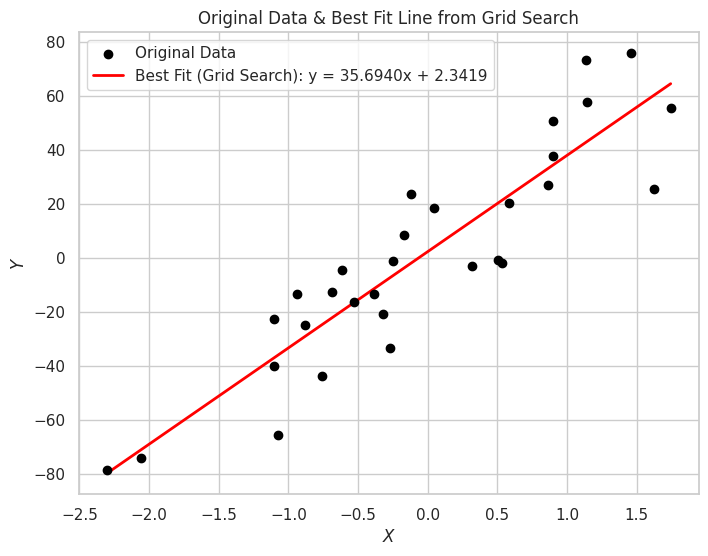

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(X_1d, Y_1d, color="black", label="Original Data", zorder=3)

# Random Grid Search의 최적 가중치와 편향을 사용해 예측선 그리기
best_w_grid = w_candidates[best_idx]
best_b_grid = b_candidates[best_idx]

X_line = np.linspace(X_1d.min(), X_1d.max(), 100)
Y_line = best_w_grid * X_line + best_b_grid

plt.plot(X_line, Y_line, color="red", linewidth=2, label=f"Best Fit (Grid Search): y = {best_w_grid:.4f}x + {best_b_grid:.4f}")

plt.xlabel("$X$")
plt.ylabel("$Y$")
plt.title("Original Data & Best Fit Line from Grid Search")
plt.legend()
plt.grid(True)
plt.show()

In [75]:
# @title **3. 직선의 절편과 기울기 search**

from sklearn.linear_model import LinearRegression

# LinearRegression 학습
reg = LinearRegression().fit(X, Y)

# 학습한 데이터 X(30, 1)와 Y(30,)에 대한 결정계수(R^2) 평가
r2_score = reg.score(X, Y)
print(f"R2 score: {r2_score:.4f}")
print(f"w (기울기): {reg.coef_[0]:.4f}")
print(f"b (절편): {reg.intercept_:.4f}")

R2 score: 0.8214
w (기울기): 35.7196
b (절편): 2.2893
x=3, x=5 예측값: [109.44805363 180.88721751]


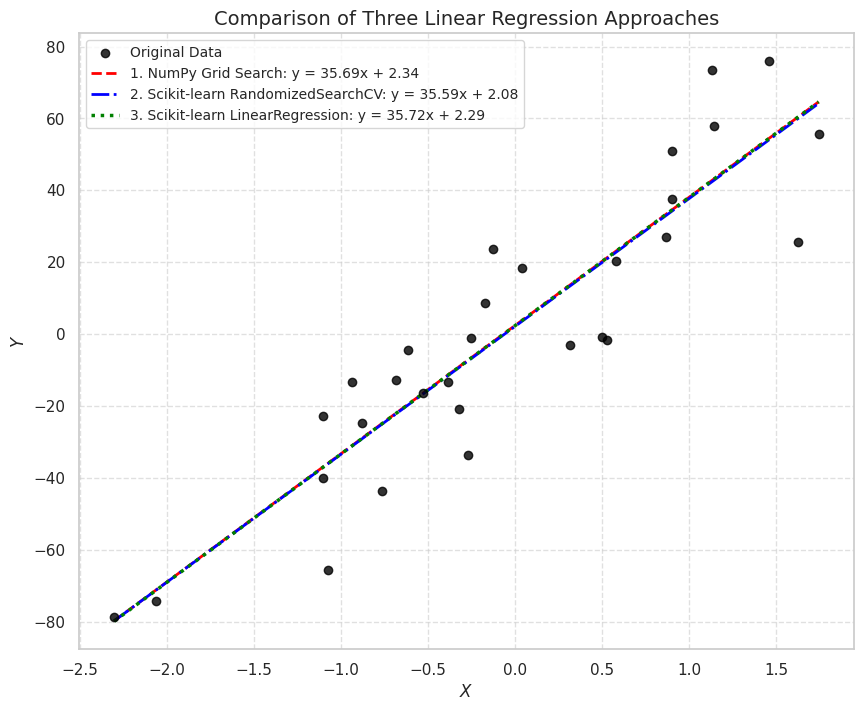

In [76]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))

# 1. 원본 데이터 산점도 그리기
plt.scatter(X_1d, Y_1d, color="black", label="Original Data", zorder=3, alpha=0.8)

# X 축 범위 설정
X_line = np.linspace(X_1d.min(), X_1d.max(), 100)

# 2. NumPy 구현 Random Grid Search 결과선 (w_candidates[best_idx], b_candidates[best_idx])
best_w_grid = w_candidates[best_idx]
best_b_grid = b_candidates[best_idx]
Y_grid = best_w_grid * X_line + best_b_grid
plt.plot(X_line, Y_grid, color="red", linestyle="--", linewidth=2,
         label=f"1. NumPy Grid Search: y = {best_w_grid:.2f}x + {best_b_grid:.2f}")

# 3. Scikit-learn RandomizedSearchCV 결과선 (best_w, best_b)
Y_rcv = best_w * X_line + best_b
plt.plot(X_line, Y_rcv, color="blue", linestyle="-.", linewidth=2,
         label=f"2. Scikit-learn RandomizedSearchCV: y = {best_w:.2f}x + {best_b:.2f}")

# 4. Scikit-learn LinearRegression 결과선 (reg.coef_, reg.intercept_)
w_lr = reg.coef_[0]
b_lr = reg.intercept_
Y_lr = w_lr * X_line + b_lr
plt.plot(X_line, Y_lr, color="green", linestyle=":", linewidth=2.5,
         label=f"3. Scikit-learn LinearRegression: y = {w_lr:.2f}x + {b_lr:.2f}")

# 그래프 스타일 설정
plt.xlabel("$X$", fontsize=12)
plt.ylabel("$Y$", fontsize=12)
plt.title("Comparison of Three Linear Regression Approaches", fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [78]:
# @title 각 3개 곡선(직선)의 MSE(Mean Squared Error) 계산

# 1. NumPy Grid Search 예측값 및 MSE
Y_pred_grid = best_w_grid * X_1d + best_b_grid
mse_grid = np.mean((Y_1d - Y_pred_grid) ** 2)

# 2. Scikit-learn RandomizedSearchCV 예측값 및 MSE
Y_pred_rcv = best_w * X_1d + best_b
mse_rcv = np.mean((Y_1d - Y_pred_rcv) ** 2)

# 3. Scikit-learn LinearRegression 예측값 및 MSE
Y_pred_lr = w_lr * X_1d + b_lr
mse_lr = np.mean((Y_1d - Y_pred_lr) ** 2)

print(f"1. NumPy Grid Search MSE: {mse_grid:.5f}")
print(f"2. Scikit-learn RandomizedSearchCV MSE: {mse_rcv:.5f}")
print(f"3. Scikit-learn LinearRegression MSE: {mse_lr:.5f}")

1. NumPy Grid Search MSE: 282.46838
2. Scikit-learn RandomizedSearchCV MSE: 282.52202
3. Scikit-learn LinearRegression MSE: 282.46478


<a name='1.2'></a>
### 1.2 - Neural Network Model with a Single Perceptron and One Input Node

The simplest neural network model has only one **perceptron**. It takes some inputs and calculates the output value.

The perceptron components are shown in the following scheme:
### **Single Perceptron Neural Networks for Linear Regression**

![](https://raw.githubusercontent.com/Ryota-Kawamura/Mathematics-for-Machine-Learning-and-Data-Science-Specialization/1a5a79553a3e2b26a0acdcd408965793b947e347/Course-1/Week-3/images/nn_model_linear_regression_simple.png)
The smallest construction block of neural networks is called a **node**. Some nodes store numbers from the input and others store the calculated values. **Input nodes** (here there is only one input node $x$) contain the input to the network which consists of your data. These nodes are set as an **input layer** of the network.

**Weight** ($w$) and **bias** ($b$) are the parameters which will get updated when you will **train** the model. They are initialized to some random value or set to 0 and updated as the training progresses. The bias is analogous to a weight independent of any input node. It makes the model more flexible.

The perceptron output calculation is straightforward: first compute the product of $x$ and weight $w$ and the add the bias:

$$z = w x + b\tag{2}$$

The **output layer** of the single perceptron has only one node $\hat{y} = z$.

Putting it all together, mathematically the single perceptron neural network model can be expressed as:

\begin{align}
z^{(i)} &=  w x^{(i)} + b,\\
\hat{y}^{(i)} &= z^{(i)},
\tag{3}\end{align}

where $x^{(i)}$ represents the $i$-th training example and $\hat{y}^{(i)}$ will be the prediction based on that example, $i = 1, \dots, m$.

If you have $m$ training examples, vector operations will give you a chance to perform the calculations simultaniously for all of them! Organise all training examples as a vector $X$ of size ($1 \times m$). Then perform scalar multiplication of $X$ ($1 \times m$) by a scalar $w$, adding $b$, which will be broadcasted to the vector of size ($1 \times m$):

\begin{align}
Z &=  w X + b,\\
\hat{Y} &= Z,
\tag{4}\end{align}

This significantly speeds up the calculations for the larger training sets! This set of calculations is called **forward propagation**.

Now, you can compare the resulting vector of the predictions $\hat{Y}$ ($1 \times m$) with the original vector of data $Y$. This can be done with the so called **cost function** that measures how close your vector of predictions to the training data. It evaluates how well the parameters $w$ and $b$ work to solve the problem. There are many different cost functions available depending on the nature of your problem. For your simple neural network you can calculate it as:

$$\mathcal{L}\left(w, b\right)  = \frac{1}{2m}\sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2.\tag{5}$$

The aim is to minimize the cost function during the training, which will minimize the differences between original values $y_i$ and predicted values $\hat{y}_i$ (division by $2m$ is taken just for scaling purposes).

When your weights were just initialized with some random values, and no training was done yet, you can't expect good results.

The next step is to adjust the weights and bias, in order to minimize the cost function. This process is called **backward propagation** and is done iteratively: you update the parameters with a small change and repeat the process.

*Note*: Backward propagation is not covered in this Course - it will be discussed in the next Course of this Specialization.

The general **methodology** to build a neural network is to:
1. Define the neural network structure ( # of input units,  # of hidden units, etc).
2. Initialize the model's parameters
3. Loop:
    - Implement forward propagation (calculate the perceptron output),
    - Implement backward propagation (to get the required corrections for the parameters),
    - Update parameters.
4. Make predictions.

You often build helper functions to compute steps 1-3 and then merge them into one function you call `nn_model()`. Once you've built `nn_model()` and learnt the right parameters, you can make predictions on new data.

<a name='2'></a>
## 2 - Implementation of the Neural Network Model for Linear Regression

Let's setup the neural network in a way which will allow to extend this simple case of a model to more complicated structures later.

<a name='2.1'></a>
### 2.1 - Defining the Neural Network Structure

Remember that your weights were just initialized with some random values, so the model has not been trained yet.

Define a cost function $(5)$ which will be used to train the model:

$$\mathcal{L}\left(w, b\right)  = \frac{1}{2m}\sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

In [88]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

# 1. 재현성을 위한 시드 고정 및 데이터 생성
tf.random.set_seed(42)

m = 30
X, Y = make_regression(n_samples=m, n_features=1, noise=20, random_state=1)

# 2. 단층 퍼셉트론(Perceptron) 모델 구성
# 입력 특성 1개(input_shape=(1,)), 출력 노드 1개(Dense(1)), 선형 활성화(activation='linear')
model = Sequential(
    [
        Input(shape=(1,)),
        Dense(units=1, activation='linear')
    ],
    name="Perceptron_Model"
)

# 3. 모델 컴파일 (타겟 Y의 스케일이 크므로 학습률 learning_rate를 0.1로 설정)
model.compile(optimizer=Adam(learning_rate=0.1), loss='mse')

# 4. 모델 학습
history = model.fit(X, Y, epochs=1000, verbose=0)

# 5. 학습된 가중치(기울기 w)와 편향(절편 b) 확인
weights, bias = model.layers[0].get_weights()
w = weights[0][0]
b = bias[0]
print(f"학습된 퍼셉트론 직선식: y = {w:.4f}x + {b:.4f}")

학습된 퍼셉트론 직선식: y = 35.6232x + 2.2835


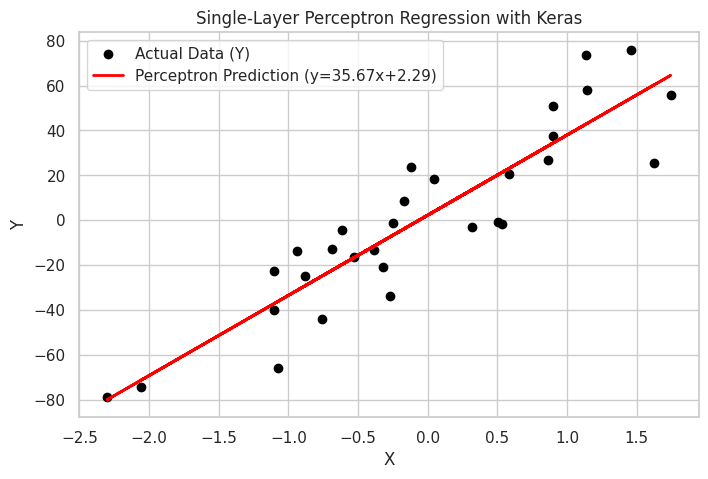

In [86]:
# 6. 예측 수행
Y_pred = model.predict(X, verbose=0)

# 7. 결과 시각화
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='black', label='Actual Data (Y)')
plt.plot(X, Y_pred, color='red', linewidth=2, label=f'Perceptron Prediction (y={w:.2f}x+{b:.2f})')
plt.title('Single-Layer Perceptron Regression with Keras')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

In [85]:
# 5. 학습된 가중치(기울기 w)와 편향(절편 b) 확인

print(f"1. NumPy Grid Search MSE: {mse_grid:.5f}")
print(f"2. Scikit-learn RandomizedSearchCV MSE: {mse_rcv:.5f}")
print(f"3. Scikit-learn LinearRegression MSE: {mse_lr:.5f}")
print(f"4. Perceptron MSE: {history.history['loss'][-1]:.4f}")

1. NumPy Grid Search MSE: 282.46838
2. Scikit-learn RandomizedSearchCV MSE: 282.52202
3. Scikit-learn LinearRegression MSE: 282.46478
4. Perceptron MSE: 282.4675


Not bad for such a small neural network with just a single perceptron and one input node!

<a name='3'></a>
## 3 - Multiple Linear Regression

Models are not always as simple as the one above. In some cases your output is dependent on more than just one variable. Let's look at the case where the output depends on two input variables.

<a name='3.1'></a>
### 3.1 - Multipe Linear Regression Model

Multiple linear regression model with two independent variables $x_1$, $x_2$ can be written as

$$\hat{y} = w_1x_1 + w_2x_2 + b = Wx + b,\tag{6}$$

where $Wx$ is the dot product of the input vector $x = \begin{bmatrix} x_1 & x_2\end{bmatrix}$ and parameters vector $W = \begin{bmatrix} w_1 & w_2\end{bmatrix}$, scalar parameter $b$ is the intercept.

The goal is the same - find the "best" parameters $w_1$, $w_2$ and $b$ such the differences between original values $y_i$ and predicted values $\hat{y}_i$ are minimum.

You can use a slightly more complicated neural network model to do that. Now matrix multiplication will be in the core of the model!

<a name='3.2'></a>
### 3.2 - Neural Network Model with a Single Perceptron and Two Input Nodes

Again, you will use only one perceptron, but with two input nodes shown in the following scheme:

The perceptron output calculation for every training example $x^{(i)} = \begin{bmatrix} x_1^{(i)} & x_2^{(i)}\end{bmatrix}$ can be written with dot product:

$$z^{(i)} = w_1x_1^{(i)} + w_2x_2^{(i)} + b = Wx^{(i)} + b,\tag{7}$$

where weights are in the vector $W = \begin{bmatrix} w_1 & w_2\end{bmatrix}$ and bias $b$ is a scalar. The output layer will have the same single node $\hat{y}^{(i)} = z^{(i)}$.

Organise all training examples in a matrix $X$ of a shape ($2 \times m$), putting $x_1^{(i)}$ and $x_2^{(i)}$ into columns. Then matrix multiplication of $W$ ($1 \times 2$) and $X$ ($2 \times m$) will give a ($1 \times m$) vector

$$WX =
\begin{bmatrix} w_1 & w_2\end{bmatrix}
\begin{bmatrix}
x_1^{(1)} & x_1^{(2)} & \dots & x_1^{(m)} \\
x_2^{(1)} & x_2^{(2)} & \dots & x_2^{(m)} \\ \end{bmatrix}
=\begin{bmatrix}
w_1x_1^{(1)} + w_2x_2^{(1)} &
w_1x_1^{(2)} + w_2x_2^{(2)} & \dots &
w_1x_1^{(m)} + w_2x_2^{(m)}\end{bmatrix}.$$

And the model can be written as

\begin{align}
Z &=  W X + b,\\
\hat{Y} &= Z,
\tag{8}\end{align}

where $b$ is broadcasted to the vector of a size ($1 \times m$). These are the calculations to perform in the forward propagation step. Cost function will remain the same, and there will be no change in methodology and training (that will be discussed in the next Course)!

In [89]:
m = 30
X, Y = make_regression(n_samples=m, n_features=3, noise=20, random_state=1)

print(f'Training dataset X: {X.shape}\n')
print(f'Training dataset Y: {Y.shape}')

Training dataset X: (30, 3)

Training dataset Y: (30,)



학습된 회귀식: y = 58.3607*x1 + 82.2196*x2 + 12.6384*x3 + 6.0194
최종 MSE Loss: 314.0679

[실제값 vs 예측값 비교 (상위 5개)]
샘플 1: 실제 Y =   49.33 | 예측 Y =   67.57
샘플 2: 실제 Y =   -1.98 | 예측 Y =    0.83
샘플 3: 실제 Y =  -98.13 | 예측 Y =  -83.44
샘플 4: 실제 Y =   16.41 | 예측 Y =   11.08
샘플 5: 실제 Y =   25.20 | 예측 Y =   27.83


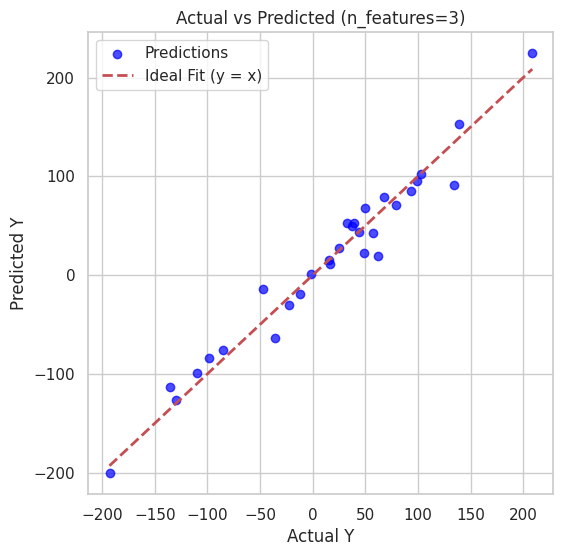

In [91]:
# @title Neural Network Model with a Single Perceptron and Three Input Nodes
# 1. 시드 고정 및 3개 특성 데이터 생성
tf.random.set_seed(42)

# 2. 다중 입력 퍼셉트론 모델 구성 (입력 3개 -> 출력 1개)
model = Sequential(
    [
        Input(shape=(3,)),
        Dense(units=1, activation='linear')
    ],
    name="Multi_Feature_Perceptron"
)

# 3. 모델 컴파일 및 학습
model.compile(optimizer=Adam(learning_rate=0.5), loss='mse')
history = model.fit(X, Y, epochs=500, verbose=0)

# 4. 학습된 가중치(w1, w2, w3)와 편향(b) 확인
weights, bias = model.layers[0].get_weights()
w1, w2, w3 = weights.flatten()
b = bias[0]

print(f"\n학습된 회귀식: y = {w1:.4f}*x1 + {w2:.4f}*x2 + {w3:.4f}*x3 + {b:.4f}")
print(f"최종 MSE Loss: {history.history['loss'][-1]:.4f}")

# 5. 예측 수행 및 실제값 비교 (상위 5개 샘플)
Y_pred = model.predict(X, verbose=0).flatten()

print("\n[실제값 vs 예측값 비교 (상위 5개)]")
for i in range(5):
    print(f"샘플 {i+1}: 실제 Y = {Y[i]:7.2f} | 예측 Y = {Y_pred[i]:7.2f}")

# 6. 실제값 vs 예측값 산점도 시각화 (3차원 입력이므로 y=x 대각선으로 일치도 확인)
plt.figure(figsize=(6, 6))
plt.scatter(Y, Y_pred, color='blue', alpha=0.7, label='Predictions')
plt.plot([Y.min(), Y.max()], [Y.min(), Y.max()], 'r--', lw=2, label='Ideal Fit (y = x)')
plt.title('Actual vs Predicted (n_features=3)')
plt.xlabel('Actual Y')
plt.ylabel('Predicted Y')
plt.legend()
plt.grid(True)
plt.show()

In [92]:
model.summary()

Model: "Multi_Feature_Perceptron"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14 (60.00 B)

 Trainable params: 4 (16.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10 (44.00 B)

## **Exercise 1.**
- 아래 그림의 네트워크 구조를 가진 코드 생성
- 입력변수 4개 sample 개수는 1000개 생성
- 회귀 생성 모델과 분류 모델 각각

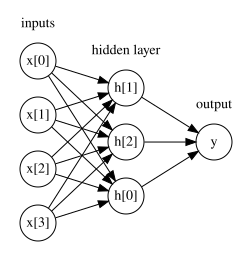

In [93]:
mglearn.plots.plot_single_hidden_layer_graph()

## **Exercise 2.**
- 아래 그림의 네트워크 구조를 가진 코드 생성
- 입력변수 4개 sample 개수는 1000개 생성
- 회귀 생성 모델과 분류 모델 각각

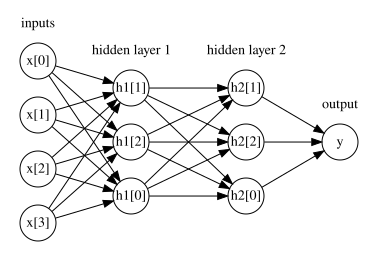

In [94]:
mglearn.plots.plot_two_hidden_layer_graph()

## **Excercise 3. 딥러닝 실습**

<img src='https://miro.medium.com/v2/resize:fit:1400/1*1zuF9G8fq3hUTafkBLcRkQ.png'>

In [95]:
# @title 데이터
import tensorflow as tf
fmnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels) ,  (test_images, test_labels) = fmnist.load_data()
training_images=training_images/255.0
test_images=test_images/255.0

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


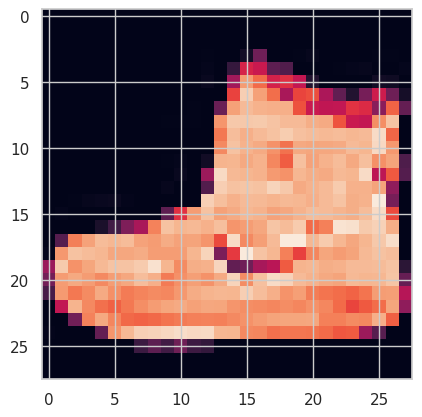

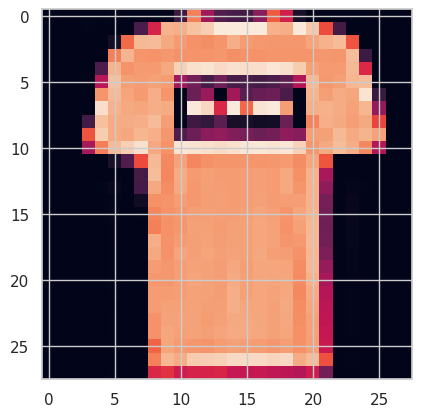

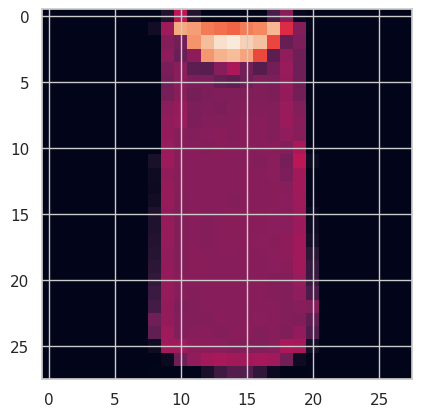

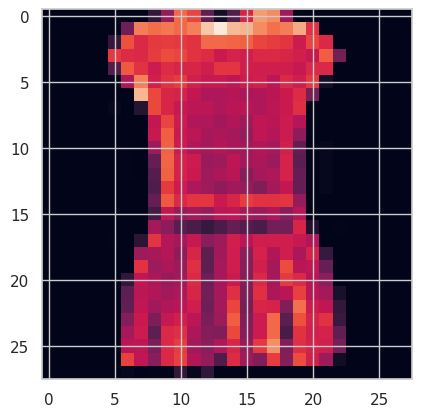

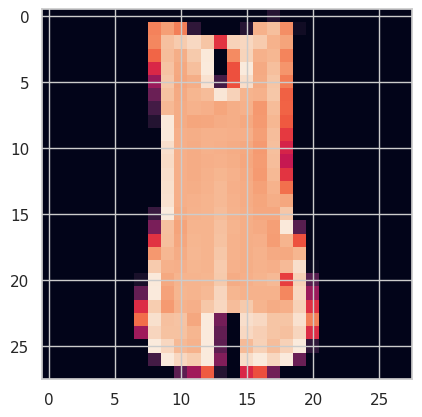

In [96]:
# @title 몇 개의 이미지 데이터를 시각화해줘

import matplotlib.pyplot as plt
for i in range(5):
    plt.imshow(training_images[i])
    plt.show()
